<a href="https://colab.research.google.com/github/a01286849-glitch/damian-garza-kosikova-A01286849/blob/main/A5_Visualizaci%C3%B3n_con_Histogramas_%26_Boxplots.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Reemplaza esta ruta por la ubicación de tu CSV
ruta = "/content/drive/MyDrive/antropometria-dataset-1-1.csv"

df = pd.read_csv(ruta)

# Quitar espacios y estandarizar los nombres de las columnas
df.columns = df.columns.str.strip().str.lower()

print("Filas y columnas:", df.shape)
display(df.head())
print("Columnas:", df.columns.tolist())

Filas y columnas: (18640, 26)


,folio,intp,entidad,desc_ent,sexo,edad,meses,peso,ropa,talla,...,hpresion,tbrazo,htension,primarylast,code_upm,est_dis,est_urb,est_marg,pondef,est_var
0,210295,2,21,PUEBLA,2,38,8,73.70,2,146.4,...,16:30,2,16:35,1,R2101,5,3,1,3470.002176,215
1,101655,3,10,DURANGO,2,11,11,35.65,2,145.1,...,15:25,3,15:25,1,M1041,1,1,1,417.946672,101
2,10287,6,1,AGUASCALIENTES,2,18,8,54.80,1,162.0,...,9:40,1,9:40,1,M0108,5,3,1,472.980811,15
3,91526,4,9,DISTRITO FEDERAL,1,10,8,33.40,2,146.5,...,7:40,3,7:45,1,M0931,4,3,2,1832.581391,94
4,210939,3,21,PUEBLA,2,19,3,97.95,2,161.0,...,6:00,2,6:00,1,M2123,5,3,1,7622.066564,215


Columnas: ['folio', 'intp', 'entidad', 'desc_ent', 'sexo', 'edad', 'meses', 'peso', 'ropa', 'talla', 'emb', 'temb', 'cintura', 'cadera', 'sistol', 'diastol', 'hpresion', 'tbrazo', 'htension', 'primarylast', 'code_upm', 'est_dis', 'est_urb', 'est_marg', 'pondef', 'est_var']


In [3]:
variables = ["peso", "cintura", "talla", "cadera"]

unidades = {
    "peso": "kg",
    "cintura": "cm",
    "talla": "cm",
    "cadera": "cm"
}

for columna in variables + ["sexo"]:
    df[columna] = pd.to_numeric(df[columna], errors="coerce")

print("Datos faltantes:")
display(df[variables].isna().sum().to_frame("Faltantes"))

print("Cantidad de registros por sexo:")
display(df["sexo"].value_counts().sort_index())

print("Estadísticas descriptivas:")
display(df[variables].describe().round(2))

Datos faltantes:


,Faltantes
peso,0
cintura,608
talla,0
cadera,608


Cantidad de registros por sexo:


,count
sexo,
1,8154
2,10486


Estadísticas descriptivas:


,peso,cintura,talla,cadera
count,18640.00,18032.00,18640.00,18032.00
mean,64.64,87.78,156.56,97.73
std,17.66,16.95,10.62,14.27
min,18.00,11.90,104.45,14.10
25%,52.70,76.00,149.40,89.75
50%,63.70,87.25,156.40,97.15
75%,75.40,98.00,163.96,105.00
max,170.60,222.22,194.50,222.22


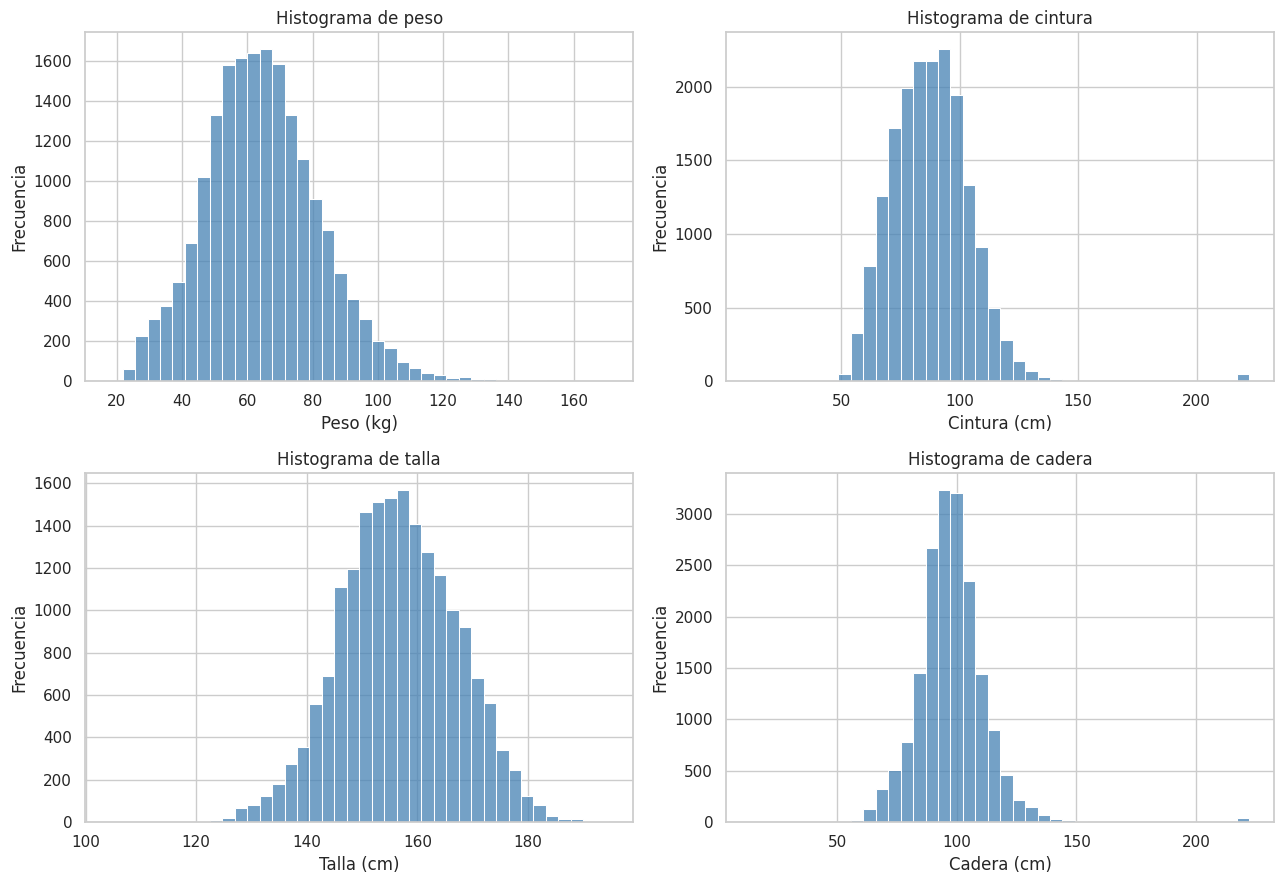

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, variable in zip(axes.flat, variables):
    sns.histplot(
        data=df,
        x=variable,
        bins=40,
        color="steelblue",
        ax=ax
    )
    ax.set_title(f"Histograma de {variable}")
    ax.set_xlabel(f"{variable.capitalize()} ({unidades[variable]})")
    ax.set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

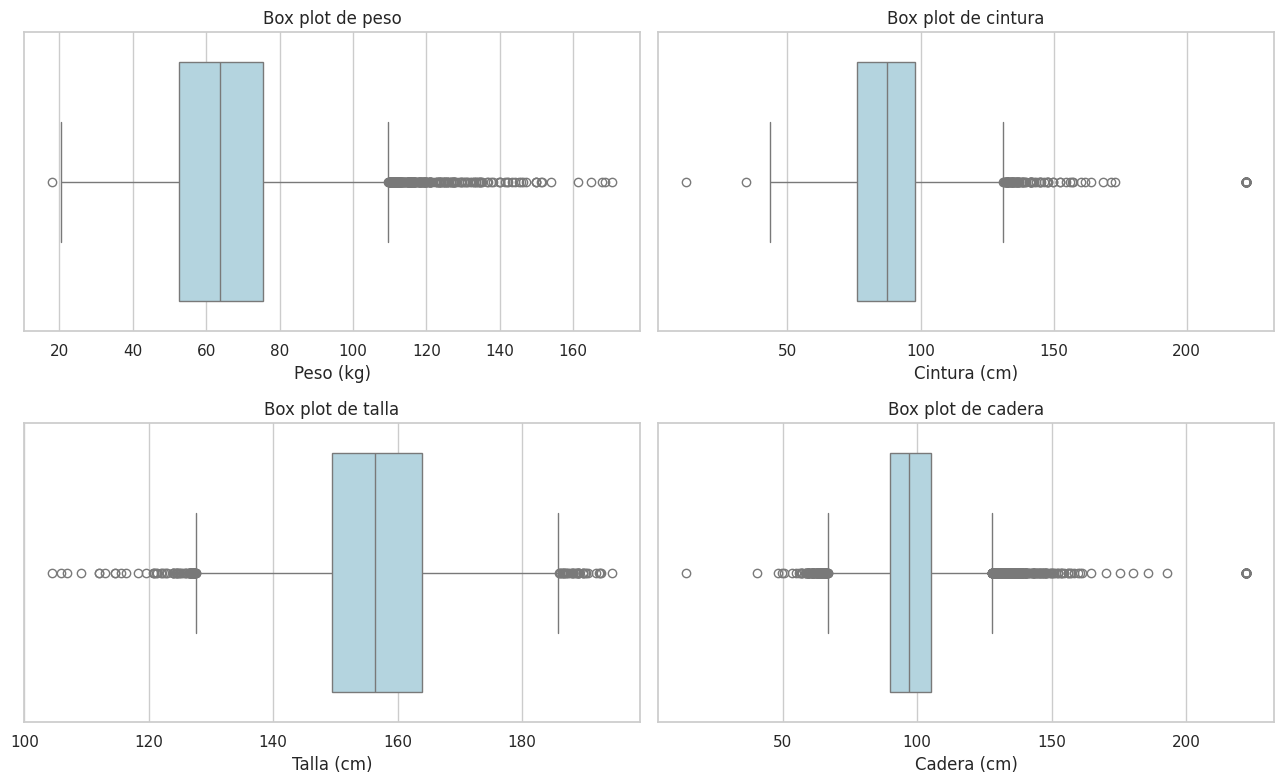

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for ax, variable in zip(axes.flat, variables):
    sns.boxplot(
        data=df,
        x=variable,
        color="lightblue",
        whis=1.5,
        ax=ax
    )
    ax.set_title(f"Box plot de {variable}")
    ax.set_xlabel(f"{variable.capitalize()} ({unidades[variable]})")

plt.tight_layout()
plt.show()

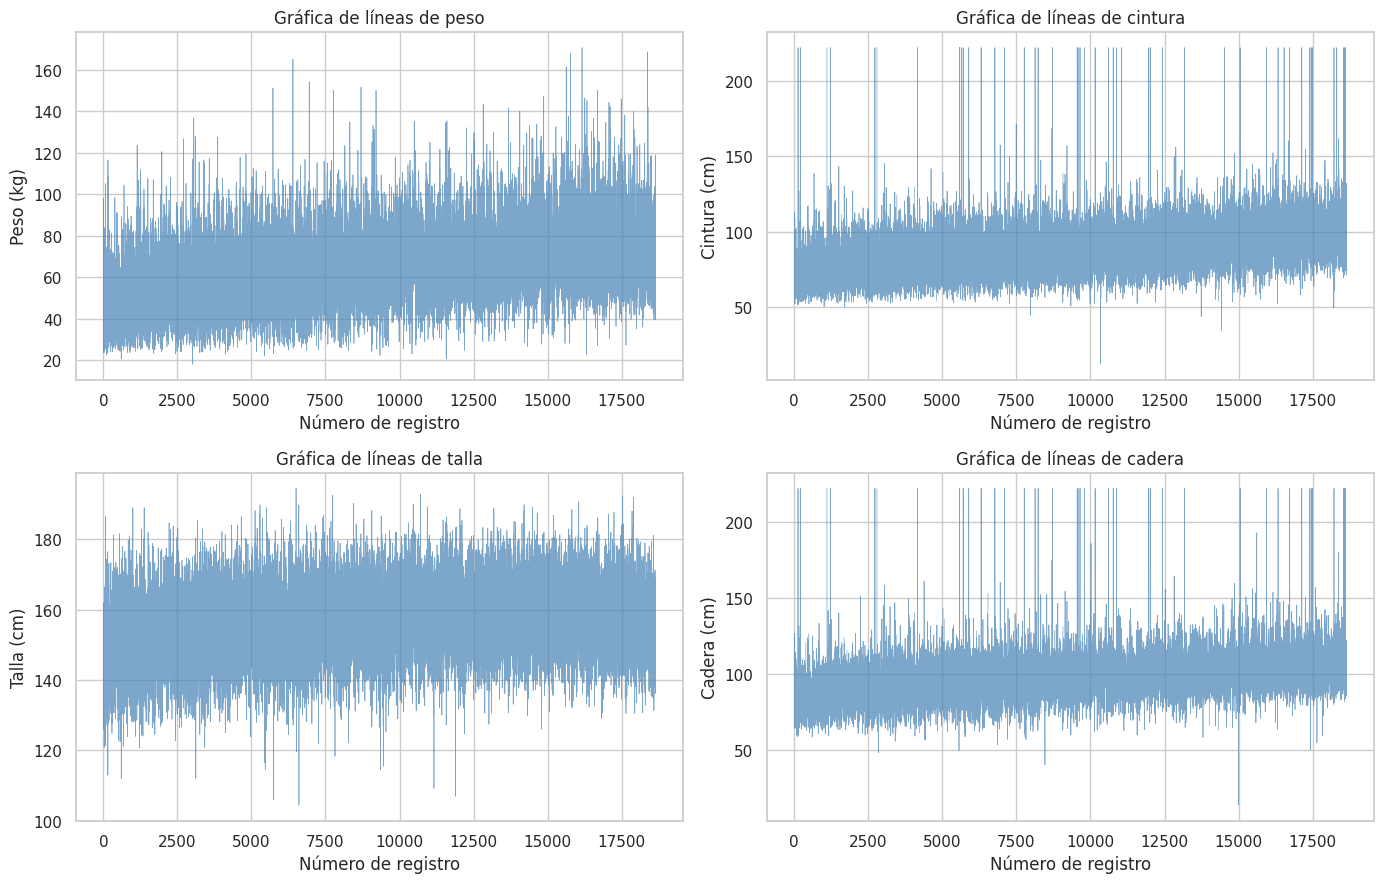

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, variable in zip(axes.flat, variables):
    ax.plot(
        np.arange(1, len(df) + 1),
        df[variable],
        color="steelblue",
        linewidth=0.5,
        alpha=0.7
    )
    ax.set_title(f"Gráfica de líneas de {variable}")
    ax.set_xlabel("Número de registro")
    ax.set_ylabel(f"{variable.capitalize()} ({unidades[variable]})")

plt.tight_layout()
plt.show()

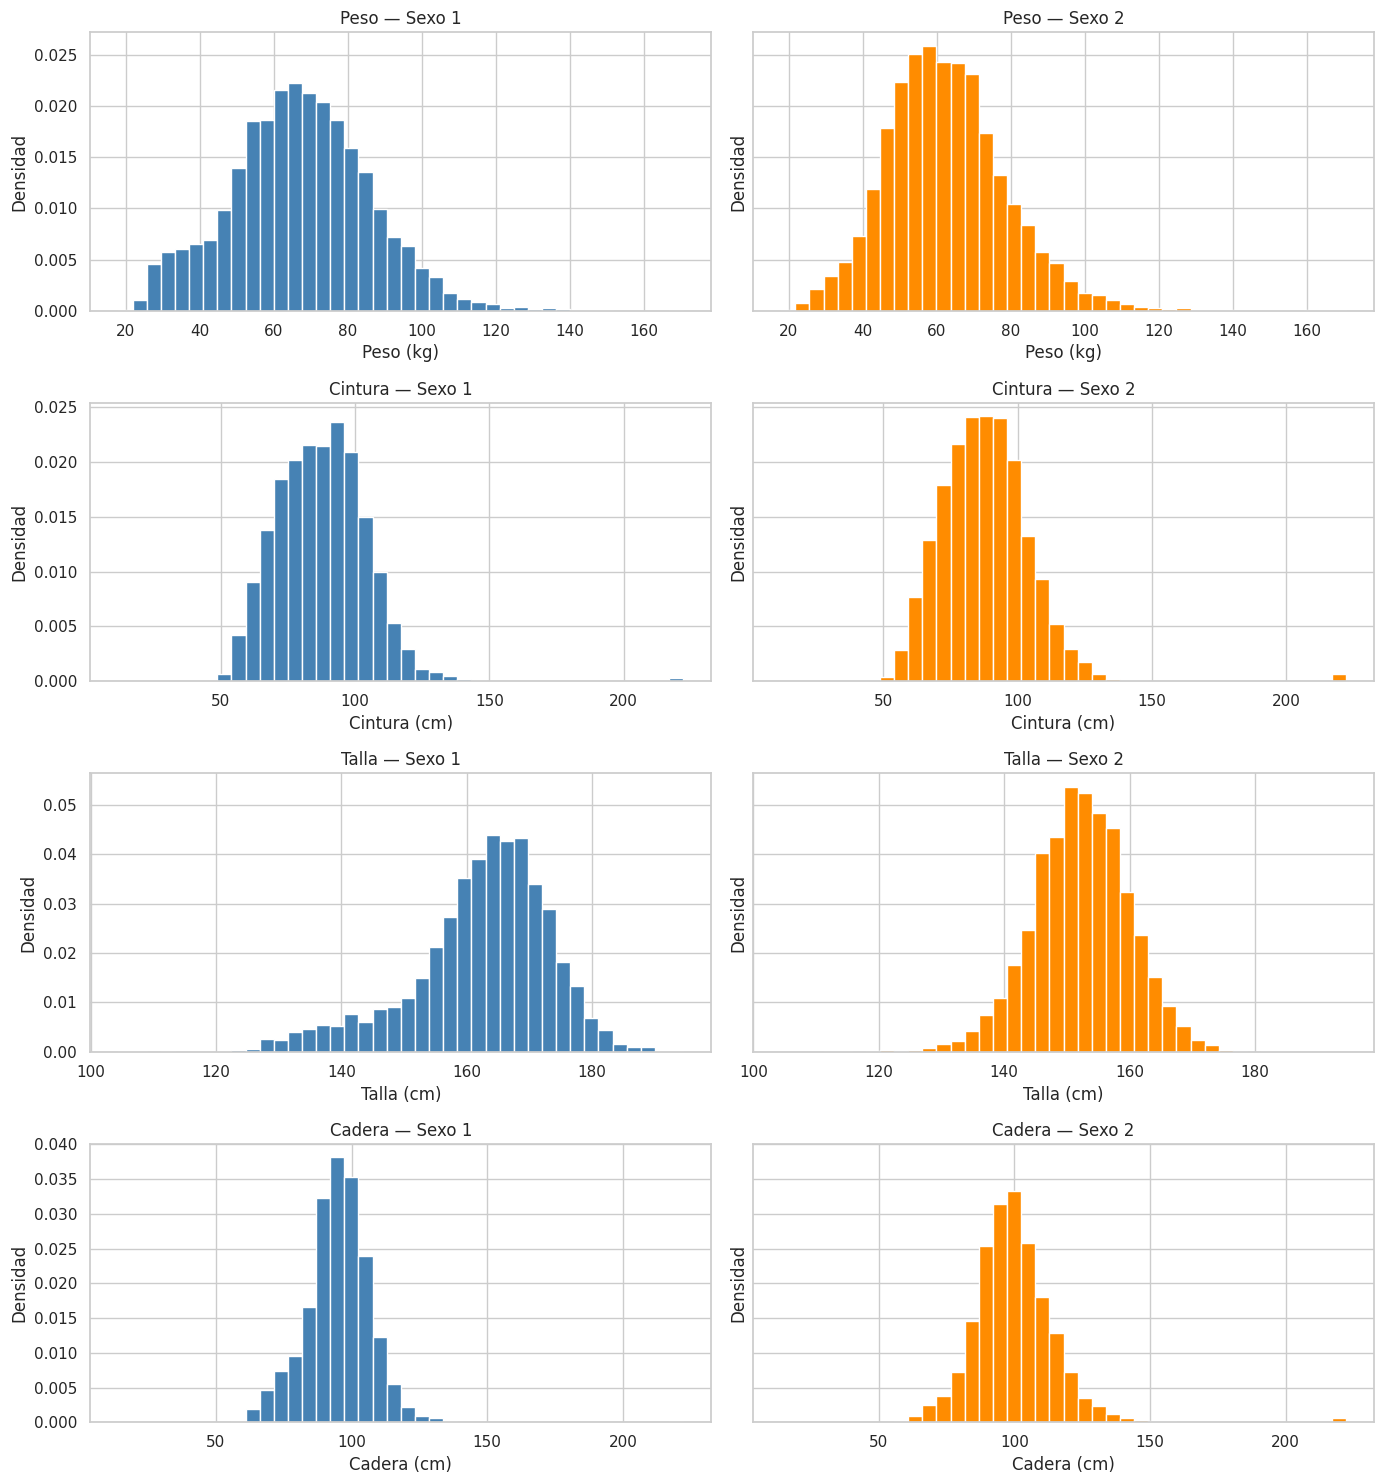

In [7]:
fig, axes = plt.subplots(
    len(variables), 2,
    figsize=(14, 15),
    sharex="row",
    sharey="row"
)

colores = {1: "steelblue", 2: "darkorange"}

for fila, variable in enumerate(variables):
    intervalos = np.histogram_bin_edges(
        df[variable].dropna(), bins=40
    )

    for columna, sexo in enumerate([1, 2]):
        grupo = df.loc[df["sexo"] == sexo, variable].dropna()

        axes[fila, columna].hist(
            grupo,
            bins=intervalos,
            density=True,
            color=colores[sexo],
            edgecolor="white"
        )
        axes[fila, columna].set_title(
            f"{variable.capitalize()} — Sexo {sexo}"
        )
        axes[fila, columna].set_xlabel(
            f"{variable.capitalize()} ({unidades[variable]})"
        )
        axes[fila, columna].set_ylabel("Densidad")

plt.tight_layout()
plt.show()

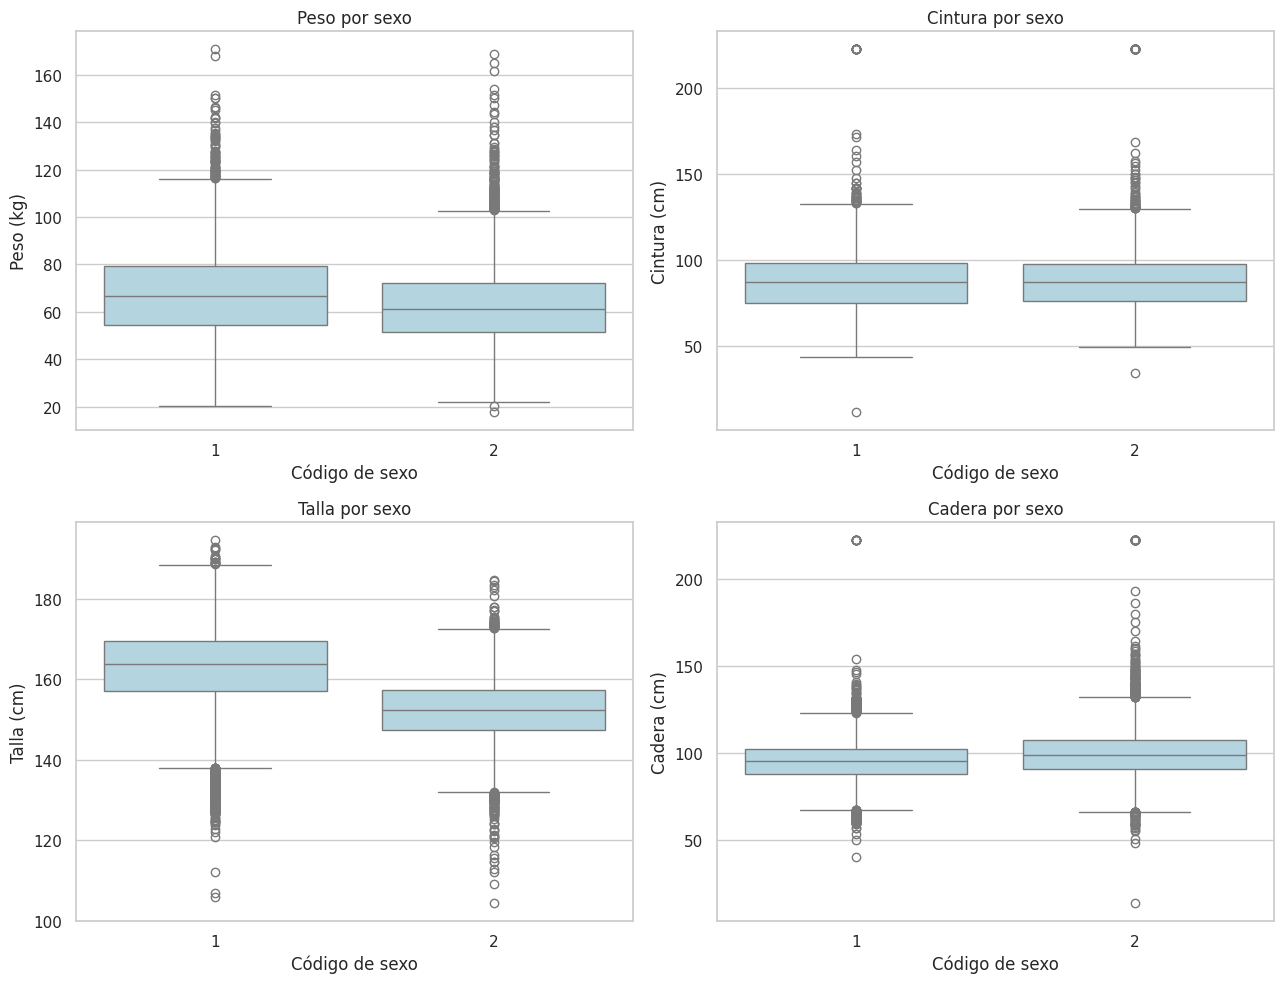

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for ax, variable in zip(axes.flat, variables):
    sns.boxplot(
        data=df,
        x="sexo",
        y=variable,
        order=[1, 2],
        color="lightblue",
        whis=1.5,
        ax=ax
    )
    ax.set_title(f"{variable.capitalize()} por sexo")
    ax.set_xlabel("Código de sexo")
    ax.set_ylabel(f"{variable.capitalize()} ({unidades[variable]})")

plt.tight_layout()
plt.show()

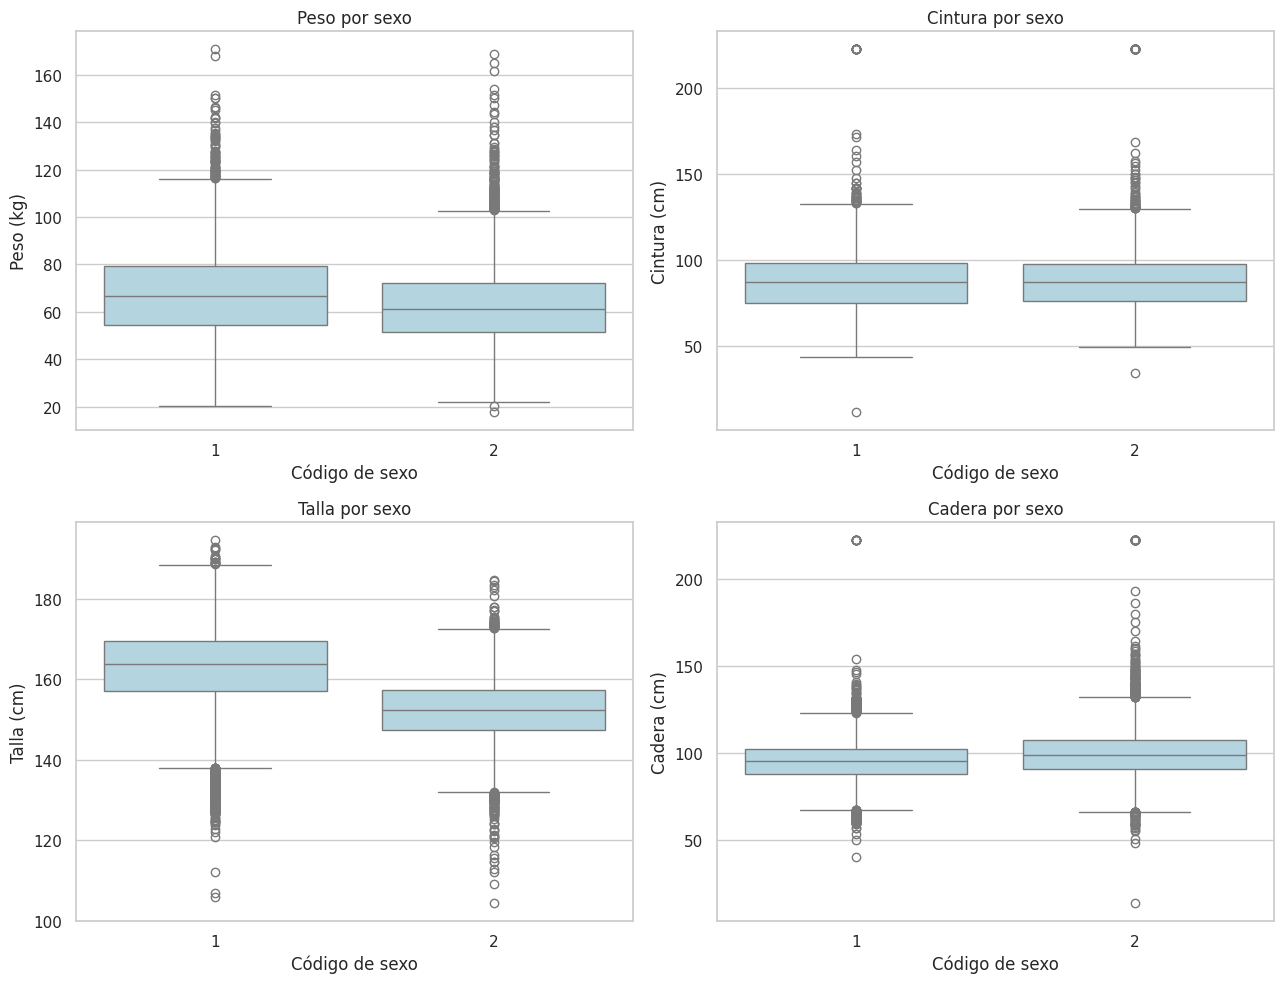

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for ax, variable in zip(axes.flat, variables):
    sns.boxplot(
        data=df,
        x="sexo",
        y=variable,
        order=[1, 2],
        color="lightblue",
        whis=1.5,
        ax=ax
    )
    ax.set_title(f"{variable.capitalize()} por sexo")
    ax.set_xlabel("Código de sexo")
    ax.set_ylabel(f"{variable.capitalize()} ({unidades[variable]})")

plt.tight_layout()
plt.show()

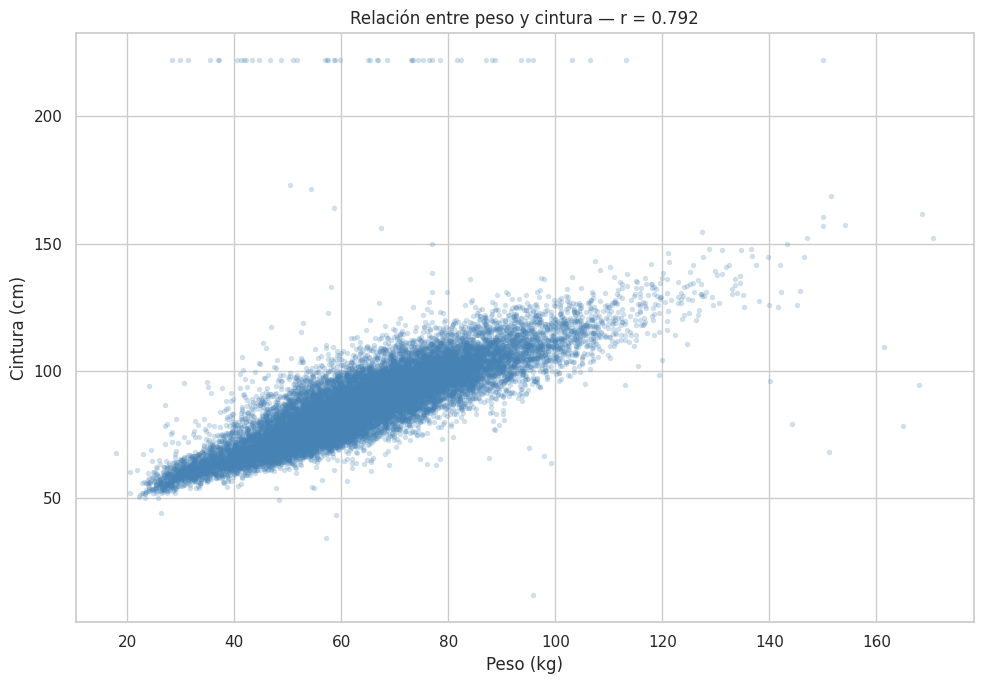

Correlación de Pearson: 0.792
Registros utilizados: 18032


In [10]:
# Usar únicamente registros que tengan peso y cintura
pares = df.dropna(subset=["peso", "cintura"])

r = pares["peso"].corr(pares["cintura"])

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pares,
    x="peso",
    y="cintura",
    color="steelblue",
    alpha=0.25,
    s=15,
    linewidth=0
)

plt.title(f"Relación entre peso y cintura — r = {r:.3f}")
plt.xlabel("Peso (kg)")
plt.ylabel("Cintura (cm)")
plt.tight_layout()
plt.show()

print(f"Correlación de Pearson: {r:.3f}")
print(f"Registros utilizados: {len(pares)}")

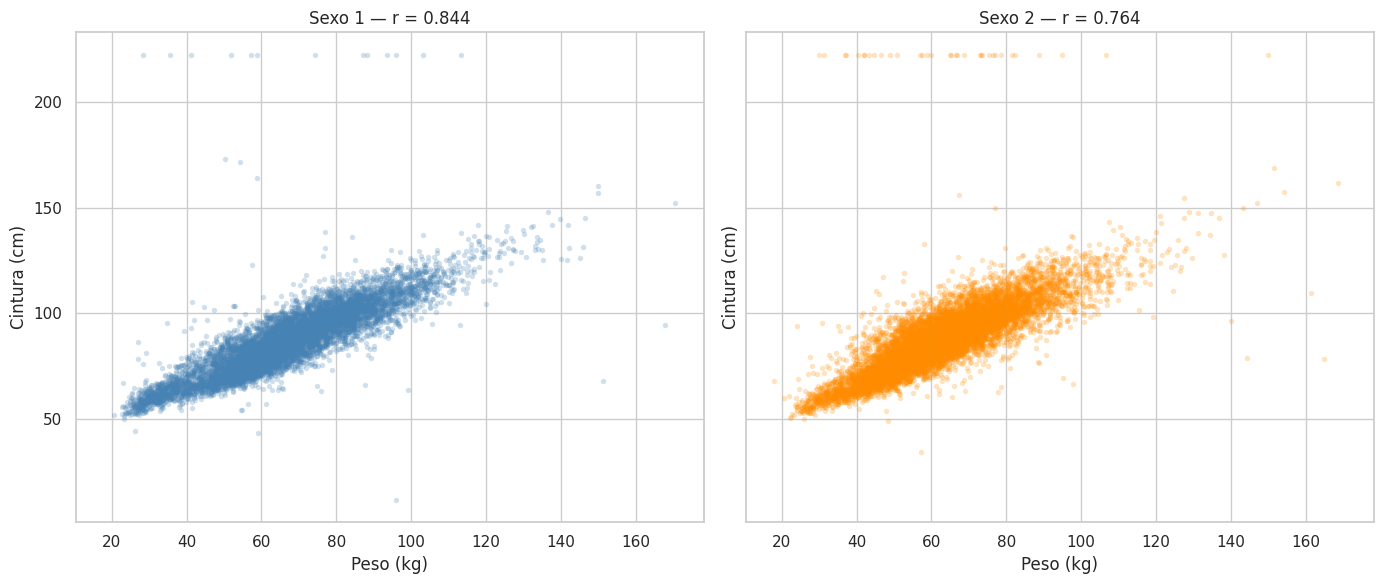

In [11]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6),
    sharex=True,
    sharey=True
)

for ax, sexo in zip(axes, [1, 2]):
    grupo = df[df["sexo"] == sexo].dropna(
        subset=["peso", "cintura"]
    )

    r = grupo["peso"].corr(grupo["cintura"])

    ax.scatter(
        grupo["peso"],
        grupo["cintura"],
        color=colores[sexo],
        alpha=0.25,
        s=15,
        linewidths=0
    )

    ax.set_title(f"Sexo {sexo} — r = {r:.3f}")
    ax.set_xlabel("Peso (kg)")
    ax.set_ylabel("Cintura (cm)")

plt.tight_layout()
plt.show()

In [12]:
resultados = []
correlaciones = []

grupos = {
    "Total": df,
    "Sexo 1": df[df["sexo"] == 1],
    "Sexo 2": df[df["sexo"] == 2]
}

for nombre, grupo in grupos.items():
    for variable in variables:
        datos = grupo[variable].dropna()

        q1 = datos.quantile(0.25)
        q3 = datos.quantile(0.75)
        ric = q3 - q1

        limite_inferior = q1 - 1.5 * ric
        limite_superior = q3 + 1.5 * ric

        atipicos = (
            (datos < limite_inferior) |
            (datos > limite_superior)
        ).sum()

        resultados.append({
            "Grupo": nombre,
            "Variable": variable,
            "N": len(datos),
            "Promedio": datos.mean(),
            "Mediana": datos.median(),
            "Asimetría": datos.skew(),
            "Posibles atípicos": atipicos
        })

    pares_grupo = grupo.dropna(subset=["peso", "cintura"])

    correlaciones.append({
        "Grupo": nombre,
        "N de pares": len(pares_grupo),
        "Correlación peso-cintura":
            pares_grupo["peso"].corr(pares_grupo["cintura"])
    })

display(pd.DataFrame(resultados).round(3))
display(pd.DataFrame(correlaciones).round(3))

,Grupo,Variable,N,Promedio,Mediana,Asimetría,Posibles atípicos
0,Total,peso,18640,64.639,63.700,0.476,223
1,Total,cintura,18032,87.779,87.250,1.467,131
2,Total,talla,18640,156.558,156.400,-0.056,102
3,Total,cadera,18032,97.734,97.150,1.721,534
4,Sexo 1,peso,8154,67.131,66.750,0.259,76
5,Sexo 1,cintura,8154,87.503,87.350,1.004,51
6,Sexo 1,talla,8154,162.138,163.800,-0.835,377
7,Sexo 1,cadera,8154,95.065,95.375,1.169,207
8,Sexo 2,peso,10486,62.701,61.450,0.631,174
9,Sexo 2,cintura,9878,88.006,87.200,1.827,86


,Grupo,N de pares,Correlación peso-cintura
0,Total,18032,0.792
1,Sexo 1,8154,0.844
2,Sexo 2,9878,0.764
